In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_7/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 4. Календарь и события

В ноутбуке 1 мы взяли праздники из библиотеки `holidays` одним бинарным флагом. Для
учебного примера этого хватило, но на практике нужен **производственный календарь**:
в нём есть то, чего библиотека не знает.

- **Нерабочие дни, а не только праздники.** Переносы выходных и длинные каникулы — это
  не праздник, а изменение режима недели.
- **Предпраздничные дни.** 31 декабря — рабочий день, но спрос ведёт себя иначе.
- **Разовые нерабочие периоды.** Ковидные «нерабочие дни» 2020 года.

Это всё по-прежнему **known-future** признаки: календарь известен на годы вперёд.

Главный навык ноутбука — **не верить названию колонки и смотреть, что в ней лежит**.

In [1]:
import common  # первым: глушит предупреждения ETNA при импорте

common.quiet()

import json  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
from etna.models import ElasticPerSegmentModel, LinearPerSegmentModel  # noqa: E402
from etna.transforms import (  # noqa: E402
    DateFlagsTransform,
    EventTransform,
    FilterFeaturesTransform,
    FourierTransform,
    HolidayTransform,
    LagTransform,
    LinearTrendTransform,
    OneHotEncoderTransform,
)

HORIZON = 14
raw = pd.read_csv(common.ROOT.parent / "data" / "onion_sales.csv", parse_dates=["day"])
raw = raw.rename(columns={"day": "timestamp", "rto": "target"}).assign(segment="onion")
onion = common.make_ts(raw)

# база: то, с чем ноутбук 2 закончил — календарь и сезонные лаги
CALENDAR = [
    LinearTrendTransform(in_column="target"),
    *common.dow(),
    FourierTransform(period=365.25, order=3, out_column="f365"),
]
LAGS = [LagTransform(in_column="target", lags=[14, 21, 28, 35, 364], out_column="lag")]
BASE = CALENDAR + LAGS

## 1. Что на самом деле лежит в производственном календаре

`calendar.json` — три списка дат:

| Ключ | Что это | В ряду 2018–2020 |
|---|---|---|
| `holidays` | все **нерабочие** дни: праздники **и** перенесённые выходные | 355 |
| `preholidays` | предпраздничные дни (сокращённый рабочий день) | 15 |
| `nowork` | разовые указы о нерабочих днях | 28 |

Сопоставим с флагом библиотеки `holidays`, которым мы пользовались в ноутбуке 1.

In [2]:
calendar = {key: pd.to_datetime(days) for key, days in json.load(open(common.ROOT.parent / "calendar.json")).items()}
dates = pd.date_range(raw["timestamp"].min(), raw["timestamp"].max() + pd.Timedelta(days=60), freq="D")

production = pd.DataFrame(
    {
        "nonworking": dates.isin(calendar["holidays"]).astype(int),
        "preholiday": dates.isin(calendar["preholidays"]).astype(int),
        "nowork": dates.isin(calendar["nowork"]).astype(int),
    },
    index=dates,
)

# флаг библиотеки holidays — на отдельном датасете: fit_transform меняет ts на месте
library = HolidayTransform(iso_code="RUS", out_column="holiday").fit_transform(common.load_onion())
library = library.to_pandas()[("onion", "holiday")].astype(int).reindex(dates, fill_value=0)

weekend = dates.dayofweek >= 5
inside = pd.Series(production.index <= raw["timestamp"].max(), index=production.index)
nonworking = (production["nonworking"] == 1) & inside

print(f"library holidays, флаг = 1:                    {library[inside].sum():>4}")
print(f"  из них на будни:                             {(library[inside].astype(bool) & ~weekend[inside]).sum():>4}")
print(f"calendar.json holidays (= нерабочие дни):       {nonworking.sum():>4}")
print(f"  из них субботы и воскресенья:                 {(nonworking & weekend).sum():>4}")
print(f"  из них будни:                                 {(nonworking & ~weekend).sum():>4}")
extra = production.index[nonworking & (library == 0) & ~weekend]
print(f"нерабочие БУДНИ, которых нет в library:          {len(extra)} — {extra.strftime('%Y-%m-%d (%a)').tolist()}")
print(f"предпраздничных дней:                           {production.loc[inside, 'preholiday'].sum():>4}")
print(f"нерабочих по указу:                             {production.loc[inside, 'nowork'].sum():>4}")

library holidays, флаг = 1:                      56
  из них на будни:                               45
calendar.json holidays (= нерабочие дни):        355
  из них субботы и воскресенья:                  309
  из них будни:                                   46
нерабочие БУДНИ, которых нет в library:          1 — ['2020-07-01 (Wed)']
предпраздничных дней:                             15
нерабочих по указу:                               28


Числа не совпадают — и это не ошибка. Источники считают **разное**:

- библиотека `holidays` помечает 56 дней — собственно праздники;
- `calendar.json` помечает 355 дней — всё, что нерабочее, включая 309 обычных суббот
  и воскресений.

Настоящая разница — в буднях: 46 нерабочих будних дней против 45 праздничных будней.
Расхождение ровно одно: **1 июля 2020** — день голосования по Конституции, объявленный
выходным, но не являющийся праздником.

Практический вывод: колонку `holidays` из производственного календаря нельзя подавать
как «флаг праздника» — получится почти копия дня недели. Её ценность в другом:
в разметке **режима работы**, и в соседних колонках `preholidays` и `nowork`.

                              count      mean
нерабочий по указу               28  126261.0
предпраздничный                  15   78924.0
нерабочий (праздник/перенос)    355   60538.0
обычный рабочий                 698   56568.0


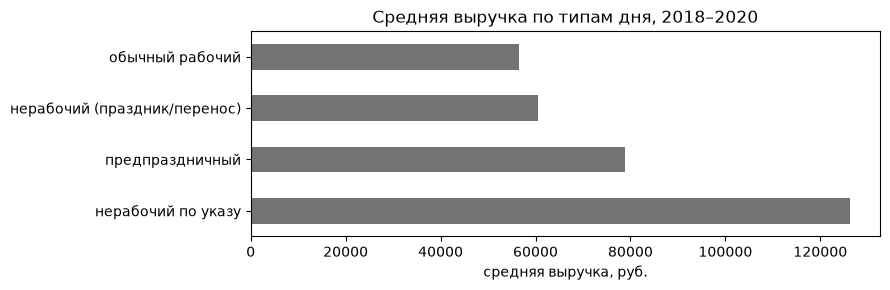

In [3]:
buckets = pd.Series("обычный рабочий", index=dates)
buckets[weekend] = "обычный выходной"
buckets[production["nonworking"] == 1] = "нерабочий (праздник/перенос)"
buckets[production["preholiday"] == 1] = "предпраздничный"
buckets[production["nowork"] == 1] = "нерабочий по указу"

daily = raw.set_index("timestamp")["target"].reindex(dates)
by_type = daily.groupby(buckets).agg(["count", "mean"]).sort_values("mean", ascending=False)
by_type["mean"] = by_type["mean"].round(0)
print(by_type.to_string())

ax = by_type["mean"].plot.barh(figsize=(9, 3), color="0.45")
ax.set_xlabel("средняя выручка, руб.")
ax.set_title("Средняя выручка по типам дня, 2018–2020")
plt.tight_layout()
plt.show()

Разброс большой и не в ту сторону, в которую можно было ожидать. Предпраздничный
рабочий день стоит на 40% дороже обычного рабочего (79 тыс. против 57 тыс.) — это и есть
сигнал, которого нет в дне недели. А «нерабочий по указу» — не дешевле, как можно
подумать про каникулы, а вдвое дороже: ковидные нерабочие дни пришлись на конец марта —
апрель 2020, когда люди скупали всё подряд. Это ровно то, почему флаг разового события
нельзя оценивать по среднему: эффект у него есть, но он не про «нерабочий день», а про
конкретные три недели 2020 года.

## 2. Какой флаг реально помогает

Подадим флаги как known-future экзогенные признаки и сравним бэктестом. Это числовые
признаки 0/1: линейная модель получает по одному коэффициенту на каждый.

In [4]:
def with_flags(columns: list[str]):
    """TSDataset с указанными флагами производственного календаря как known-future exog."""
    exog = production[columns].reset_index(names="timestamp").assign(segment="onion")
    return common.make_ts(raw, exog=exog)


BINARY = HolidayTransform(iso_code="RUS", out_column="holiday")

results = {
    "календарь + лаги": common.backtest(LinearPerSegmentModel(), BASE, onion, HORIZON),
    "+ праздник (library)": common.backtest(LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS, onion, HORIZON),
    "+ нерабочий день (calendar)": common.backtest(
        LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS, with_flags(["nonworking"]), HORIZON
    ),
    "+ предпраздничный": common.backtest(
        LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS, with_flags(["preholiday"]), HORIZON
    ),
    "+ нерабочий по указу": common.backtest(
        LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS, with_flags(["nowork"]), HORIZON
    ),
    "+ предпраздничный + по указу": common.backtest(
        LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS, with_flags(["preholiday", "nowork"]), HORIZON
    ),
}
common.compare(results)

,WAPE,MAE
календарь + лаги,0.1047,7859.7922
+ праздник (library),0.0947,7053.1767
+ нерабочий день (calendar),0.0947,7054.9176
+ предпраздничный,0.0907,6733.4460
+ нерабочий по указу,0.0967,7280.2511
+ предпраздничный + по указу,0.0937,7020.3720


Два результата, которые стоит обсудить.

**`preholiday` — единственный новый сигнал.** Флаг библиотеки даёт 0.0947, предпраздничный
день — 0.0907. Причина видна в таблице выше: предпраздничный день — это рабочий день,
которого нет ни в одном флаге `holidays`, но спрос в нём ведёт себя как в праздничный.

**`nowork` вредит.** 28 ковидных дней 2020 года — разовое событие. Линейная модель не
может выучить «режим пандемии» из флага: она получит один усреднённый сдвиг, который на
остальных фолдах не работает. Это общее правило: **признак под разовое событие хуже, чем
отсутствие признака**, если событие не повторяется в обучающей истории.

## 3. Как кодировать сам праздник

`HolidayTransform` умеет три режима:

| Режим | Что даёт | Когда нужен |
|---|---|---|
| `binary` | флаг 0/1 | праздник влияет однородно |
| `category` | название праздника → one-hot | у Нового года и 8 марта эффект разный |
| `days_count` | число праздничных дней в периоде | **только для weekly и реже** |

`days_count` на дневных данных падает: ETNA считает его по календарным периодам, а не по
дням. Для дневного ряда эквивалент — ручной счётчик дней до/после праздника (ниже).

Режим `category` даёт по признаку на каждый праздник. Это больше параметров, и вопрос,
окупается ли это, решает бэктест — а не интуиция «больше информации лучше».

In [5]:
CATEGORY = [
    HolidayTransform(iso_code="RUS", mode="category", out_column="hol"),
    OneHotEncoderTransform(in_column="hol", out_column="hol_ohe"),
    FilterFeaturesTransform(exclude=["hol"]),
]
try:
    HolidayTransform(iso_code="RUS", mode="days_count", out_column="hc").fit_transform(common.load_onion())
except ValueError as error:
    print("days_count на дневных данных:", str(error).splitlines()[0])

modes = {
    "binary": common.backtest(LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS, onion, HORIZON),
    "category (OLS)": common.backtest(LinearPerSegmentModel(), CALENDAR + CATEGORY + LAGS, onion, HORIZON),
}
for alpha in (0.01, 0.1, 1.0):
    modes[f"category + Ridge a={alpha}"] = common.backtest(
        ElasticPerSegmentModel(alpha=alpha, l1_ratio=0.0), CALENDAR + CATEGORY + LAGS, onion, HORIZON
    )
model = modes["category (OLS)"]["pipelines"][0].model._models["onion"]
print("\nпризнаков в модели с категориями:", len(model.regressor_columns))
common.compare(modes)

days_count на дневных данных: Days_count mode works only with weekly, monthly, quarterly or yearly data. You have freq=D



признаков в модели с категориями: 41


,WAPE,MAE
binary,0.0947,7053.1767
category (OLS),0.0991,7208.4877
category + Ridge a=0.01,0.0954,7012.6548
category + Ridge a=0.1,0.0972,7198.1554
category + Ridge a=1.0,0.1042,7671.0889


`category` **проигрывает** простому флагу: 0.0991 против 0.0947 при 41 признаке на
~1000 наблюдений. Регуляризация возвращает часть разницы (лучший Ridge на 0.01 — 0.0954),
но обогнать `binary` не может.

Мораль не в том, что «категории плохие». Мораль в том, что **признак, который кажется
информативнее, может оказаться хуже**: чтобы оценить эффект 8 марта отдельно от Нового
года, нужно много наблюдений на каждый праздник, а их нет. Решает бэктест, а не
рассуждение о том, сколько информации в признаке.

## 4. Расстояние до события: `EventTransform`

Флаг «сегодня праздник» не говорит, что было вчера и что будет завтра. `EventTransform`
строит по **бинарному** флагу признаки окрестности события: `n_pre` дней до и `n_post`
дней после.

В режиме `binary` это отдельные флаги «за k дней до события» — модель выучит форму
нарастания сама. В режиме `distance` — одно число: **`1 / расстояние`**, убывающее от 1
к 0 по мере удаления. Это не число дней, и это важно помнить.

Трансформ всегда создаёт **две** колонки — `<out_column>_pre` и `<out_column>_post`:
«закупились заранее» и «спрос просел после» — разные эффекты с разными коэффициентами.
Входная колонка должна быть именно **бинарной**: от `mode="category"` он падает.

In [6]:
event_tr = EventTransform(in_column="holiday", out_column="event", mode="distance", n_pre=14, n_post=7)
demo = common.load_onion()  # отдельная копия: fit_transform меняет ts на месте
for transform in (HolidayTransform(iso_code="RUS", out_column="holiday"), event_tr):
    transform.fit_transform(demo)

window = demo.to_pandas()["onion"].loc["2019-12-18":"2020-01-12", ["holiday", "event_pre", "event_post"]]
print(window.round(3).to_string())

results["+ distance до праздника"] = common.backtest(
    LinearPerSegmentModel(), CALENDAR + [BINARY, event_tr] + LAGS, onion, HORIZON
)
common.compare(results)

feature    holiday  event_pre  event_post
timestamp                                
2019-12-18       0      0.071       0.000
2019-12-19       0      0.077       0.000
2019-12-20       0      0.083       0.000
2019-12-21       0      0.091       0.000
2019-12-22       0      0.100       0.000
2019-12-23       0      0.111       0.000
2019-12-24       0      0.125       0.000
2019-12-25       0      0.143       0.000
2019-12-26       0      0.167       0.000
2019-12-27       0      0.200       0.000
2019-12-28       0      0.250       0.000
2019-12-29       0      0.333       0.000
2019-12-30       0      0.500       0.000
2019-12-31       0      1.000       0.000
2020-01-01       1      0.000       0.000
2020-01-02       1      0.000       0.000
2020-01-03       1      0.000       0.000
2020-01-04       1      0.000       0.000
2020-01-05       1      0.000       0.000
2020-01-06       1      0.000       0.000
2020-01-07       1      0.000       0.000
2020-01-08       1      0.000     

,WAPE,MAE
календарь + лаги,0.1047,7859.7922
+ праздник (library),0.0947,7053.1767
+ нерабочий день (calendar),0.0947,7054.9176
+ предпраздничный,0.0907,6733.4460
+ нерабочий по указу,0.0967,7280.2511
+ предпраздничный + по указу,0.0937,7020.3720
+ distance до праздника,0.0944,7003.0285


Видно устройство признака: 31 декабря `event_pre = 1.0` (один день до праздника), 30-го —
0.5, 29-го — 0.333. Внутри самого праздника окрестность обнуляется, а после него
начинает работать `event_post`.

Выигрыша здесь нет (0.0944 против 0.0907 у `preholiday`). Причина та же, что в ноутбуке 1:
`1/расстояние` одинаково для всех праздников, а нарастание спроса у Нового года и у 8 марта
разное. Один общий гиперболический шаблон это не описывает — а ручные индикаторы
«за k дней до Нового года» из ноутбука 1 описывают.

## 5. Полный набор флагов даты

`DateFlagsTransform` умеет больше, чем день недели: номер дня в месяце и в году, номер
недели, сезон, флаг выходного, «особые дни месяца» (например, `08.03`). Часть этого
дублирует тренд и Фурье, часть — конфликтует с ними.

Кандидат на пользу — `day_number_in_month`: конец месяца связан с зарплатами и закупками,
и это цикл, которого нет ни в дне недели, ни в годовом Фурье.

In [7]:
flags = DateFlagsTransform(
    day_number_in_week=False,
    day_number_in_month=True,
    day_number_in_year=True,
    week_number_in_month=True,
    week_number_in_year=True,
    month_number_in_year=True,
    is_weekend=True,
    season_number=True,
    special_days_in_month=("23.02", "08.03", "01.01"),
    out_column="df",
)
results["+ флаги даты"] = common.backtest(
    LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS + [flags], onion, HORIZON
)
results["+ флаги даты + предпраздничный"] = common.backtest(
    LinearPerSegmentModel(), CALENDAR + [BINARY] + LAGS + [flags], with_flags(["preholiday"]), HORIZON
)
common.compare(results)

,WAPE,MAE
календарь + лаги,0.1047,7859.7922
+ праздник (library),0.0947,7053.1767
+ нерабочий день (calendar),0.0947,7054.9176
+ предпраздничный,0.0907,6733.4460
+ нерабочий по указу,0.0967,7280.2511
+ предпраздничный + по указу,0.0937,7020.3720
+ distance до праздника,0.0944,7003.0285
+ флаги даты,0.0952,6671.3346
+ флаги даты + предпраздничный,0.0927,6489.7573


Полный набор флагов даты **не помогает**: 0.0952 против 0.0947 у одного праздника, а с
`preholiday` — 0.0927 против 0.0907. Причина в дублировании: `month_number`,
`season_number` и `day_number_in_year` — это грубые версии годового Фурье, `is_weekend` —
комбинация уже имеющегося дня недели. Модель получает несколько почти одинаковых
признаков и делит между ними один и тот же эффект, увеличивая дисперсию оценки.

`day_number_in_month` — единственный кандидат, у которого нет дубля. Но он один не
окупает остальные 20 флагов, которые тянутся в модель вместе с ним. Если он нужен —
его стоит подавать отдельно, а не всей пачкой.

Это тот же урок, что и с `category`: **больше признаков ≠ лучше прогноз**. Разница в
том, что здесь лишние признаки не независимы, а дублируют друг друга.

## Итог

| Что добавили | WAPE | Зачем |
|---|---|---|
| календарь + сезонные лаги (база) | 0.1047 | — |
| + праздник (`HolidayTransform`) | 0.0947 | праздник как однородный эффект |
| + **предпраздничный** (`calendar.json`) | **0.0907** | эффект **до** праздника |
| + нерабочий день (`calendar.json`) | 0.0947 | дубль дня недели, пользы нет |
| + нерабочий по указу | 0.0967 | разовое событие, модель его не выучит |
| + `EventTransform` distance | 0.0944 | окрестность события одним числом |
| + флаги даты | 0.0952 | циклы длиннее недели |

Что стоит запомнить:

1. **Читайте данные, а не названия.** Колонка `holidays` в производственном календаре —
   это нерабочие дни (355), а не праздники (56). Подать её как флаг праздника — значит
   почти продублировать день недели.
2. **Библиотека праздников ≠ производственный календарь.** Переносы выходных,
   предпраздничные и разовые нерабочие дни библиотека не знает.
3. **`category` — не автоматически лучше `binary`.** Больше признаков — больше дисперсии
   оценки. Сравнивайте бэктестом, регуляризация может частично вернуть выигрыш, но не
   обязана.
4. **Разовые события не обобщаются.** Признак под событие, которого не было в обучающей
   истории, добавляет шума, а не информации.
5. **Режимы важны.** `days_count` — только weekly и реже; `EventTransform` требует
   бинарную колонку и создаёт две: `_pre` и `_post`.

Дальше — признаки, которых нет в библиотеке вообще: отношения и разности признаков,
взаимодействия и декомпозиция ряда (ноутбук 5).